# Анализ рынка недвижимости Москвы


In [1]:
import pandas as pd 
import numpy as np
from numpy import radians, sin, cos, sqrt, arcsin
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, mannwhitneyu

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
df = pd.read_csv("realty_data.csv")

df.head()

,product_name,period,price,postcode,address_name,lat,lon,object_type,total_square,rooms,floor,city,settlement,district,area,description,source
0,"3-комнатная, 137 м²",NaN,63000000,"127,473.00","2-й Щемиловский переулок, 5а",55.78,37.61,Квартира,137.00,3.00,6.00,Москва,NaN,Тверской район,NaN,Просторная квартира свободной планировки с пан...,ЦИАН
1,"Студия, 16,7 м²",NaN,3250000,"108,815.00","Харлампиева, 46",55.55,37.31,Квартира,16.70,NaN,1.00,Москва,NaN,Филимонковское поселение,NaN,ВНИМАНИЕ! ОЧЕНЬ ПРИВЛЕКАТЕЛЬНОЕ ПРЕ...,Домклик
2,"3-комнатная, 76 м²",NaN,16004680,NaN,"ЖК Прокшино, 8 к4",55.59,37.43,Квартира,76.00,3.00,6.00,Москва,NaN,Сосенское поселение,NaN,"Apт.1684018. 0,01% - гибкая ипотека! Воспользу...",Яндекс.Недвижимость
3,"1-комнатная, 24 м²",NaN,7841776,NaN,"ЖК Прокшино, 6 к2",55.59,37.43,Квартира,24.00,1.00,10.00,Москва,NaN,Сосенское поселение,NaN,Продается однокомнатная квартира № 381 в новос...,Новострой-М
4,"3-комнатная, 126 м²",NaN,120000000,"121,352.00","Давыдковская, 18",55.72,37.46,Квартира,126.00,3.00,16.00,Москва,NaN,Фили-Давыдково район,NaN,Шикарное предложение!\nПродаётся трёхкомнатная...,Домклик


In [2]:
print(f"Размер датасета: {df.shape[0]:,} строк и {df.shape[1]} столбцов")
df.info()

Размер датасета: 98,822 строк и 17 столбцов
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98822 entries, 0 to 98821
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_name  98822 non-null  object 
 1   period        0 non-null      float64
 2   price         98822 non-null  int64  
 3   postcode      93675 non-null  float64
 4   address_name  98821 non-null  object 
 5   lat           98822 non-null  float64
 6   lon           98822 non-null  float64
 7   object_type   98822 non-null  object 
 8   total_square  98822 non-null  float64
 9   rooms         94840 non-null  float64
 10  floor         98822 non-null  float64
 11  city          91928 non-null  object 
 12  settlement    6894 non-null   object 
 13  district      75111 non-null  object 
 14  area          19498 non-null  object 
 15  description   98573 non-null  object 
 16  source        98822 non-null  object 
dtypes: float64(7), int64(1), 

In [3]:
df.describe(include="all").T #сводная статистика по всем столбцам

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_name,98822,5827,"1-комнатная, 38 м²",954,NaN,NaN,NaN,NaN,NaN,NaN,NaN
period,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,"98,822.00",NaN,NaN,NaN,"25,121,223.80","36,072,335.99","1,900,000.00","10,500,000.00","15,167,126.00","25,000,000.00","1,155,219,000.00"
postcode,"93,675.00",NaN,NaN,NaN,"124,503.59","11,956.74","101,000.00","115,516.00","123,154.00","140,003.00","143,989.00"
address_name,98821,22083,"улица Академика Королёва, 21",1203,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,"98,822.00",NaN,NaN,NaN,55.74,0.11,55.47,55.67,55.75,55.82,56.03
lon,"98,822.00",NaN,NaN,NaN,37.59,0.17,37.14,37.47,37.57,37.69,38.12
object_type,98822,1,Квартира,98822,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_square,"98,822.00",NaN,NaN,NaN,66.09,48.82,8.00,40.10,56.40,75.70,"2,070.00"
rooms,"94,840.00",NaN,NaN,NaN,2.20,1.04,1.00,1.00,2.00,3.00,15.00


Столбец period имеет ноль значений 
object_type имеет только одно значение - квартира 
city указана чаще всего Москва 
Больше всего объявлений с ЦИАН 
Средняя цена квартиры примерно 25.1 млн и 75% квартир дешевле 25 млн (самая дорогая квартира - 1.155 млрд)
Средняя площадь: 66.1 м2м, медиана: 56.4 м2 75% квартир меньше примерно 75.7 м2 
Чаще продаются 2х комнатные квартиры, а максимум — 15 комнат

In [4]:
q = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
}).sort_values("missing_%", ascending=False)
q

,missing,missing_%
period,98822,100.00
settlement,91928,93.02
area,79324,80.27
district,23711,23.99
city,6894,6.98
postcode,5147,5.21
rooms,3982,4.03
description,249,0.25
product_name,0,0.00
total_square,0,0.00


In [5]:
print("\nГорода:")
display(df["city"].value_counts(dropna=False).head(20))


Города:


city
Москва          73180
NaN              6894
Балашиха         2914
Химки            2330
Люберцы          1965
Красногорск      1772
Мытищи           1708
Одинцово         1247
Королёв           981
Котельники        897
Долгопрудный      761
Видное            682
Московский        653
Реутов            581
Щёлково           457
Пушкино           419
Лобня             407
Ивантеевка        293
Щербинка          233
Дзержинский       181
Name: count, dtype: int64

In [6]:
flats = df[df["city"] == "Москва"].copy() #оставляем объявления только по Москве
drop_columns = [col for col in ["period"] if col in flats.columns] #убираем пустой столбец
flats = flats.drop(columns=drop_columns)
flats.head()

,product_name,price,postcode,address_name,lat,lon,object_type,total_square,rooms,floor,city,settlement,district,area,description,source
0,"3-комнатная, 137 м²",63000000,"127,473.00","2-й Щемиловский переулок, 5а",55.78,37.61,Квартира,137.00,3.00,6.00,Москва,NaN,Тверской район,NaN,Просторная квартира свободной планировки с пан...,ЦИАН
1,"Студия, 16,7 м²",3250000,"108,815.00","Харлампиева, 46",55.55,37.31,Квартира,16.70,NaN,1.00,Москва,NaN,Филимонковское поселение,NaN,ВНИМАНИЕ! ОЧЕНЬ ПРИВЛЕКАТЕЛЬНОЕ ПРЕ...,Домклик
2,"3-комнатная, 76 м²",16004680,NaN,"ЖК Прокшино, 8 к4",55.59,37.43,Квартира,76.00,3.00,6.00,Москва,NaN,Сосенское поселение,NaN,"Apт.1684018. 0,01% - гибкая ипотека! Воспользу...",Яндекс.Недвижимость
3,"1-комнатная, 24 м²",7841776,NaN,"ЖК Прокшино, 6 к2",55.59,37.43,Квартира,24.00,1.00,10.00,Москва,NaN,Сосенское поселение,NaN,Продается однокомнатная квартира № 381 в новос...,Новострой-М
4,"3-комнатная, 126 м²",120000000,"121,352.00","Давыдковская, 18",55.72,37.46,Квартира,126.00,3.00,16.00,Москва,NaN,Фили-Давыдково район,NaN,Шикарное предложение!\nПродаётся трёхкомнатная...,Домклик


In [7]:
flats["price_mln"] = flats["price"] / 1_000_000 #цена в миллионах
flats["price_m2"] = flats["price"] / flats["total_square"] #цена м2
flats["price_m2_t"] = flats["price_m2"] / 1_000 #тысячи рублей за м2

flats[["price", "price_mln", "total_square", "price_m2", "price_m2_t"]].head()

,price,price_mln,total_square,price_m2,price_m2_t
0,63000000,63.00,137.00,"459,854.01",459.85
1,3250000,3.25,16.70,"194,610.78",194.61
2,16004680,16.00,76.00,"210,587.89",210.59
3,7841776,7.84,24.00,"326,740.67",326.74
4,120000000,120.00,126.00,"952,380.95",952.38


In [8]:
print("Объявления - дубликаты:", df.duplicated().sum())

potential_d = df.duplicated(subset=["address_name", "total_square", "price", "rooms", "floor"]).sum()

print("Потенциальные дубликаты", potential_d)

Объявления - дубликаты: 0
Потенциальные дубликаты 1


In [9]:
print("Цена <= 0 у", (flats["price"] <= 0).sum(), "объектов") #некорректные значения
print("Площадь <= 0 у", (flats["total_square"] <= 0).sum(), "объектов")
print("Этаж <= 0 у", (flats["floor"] <= 0).sum(), "объектов")


Цена <= 0 у 0 объектов
Площадь <= 0 у 0 объектов
Этаж <= 0 у 0 объектов


In [10]:
stats = flats[["price_mln", "total_square", "rooms", "floor"]].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99])

stats = stats.rename(columns={
    "price_mln": "Цена, млн ₽",
    "total_square": "Площадь, м²",
    "rooms": "Комнаты",
    "floor": "Этаж"
})
stats

,"Цена, млн ₽","Площадь, м²",Комнаты,Этаж
count,"73,180.00","73,180.00","70,952.00","73,180.00"
mean,30.19,69.95,2.28,10.43
std,40.47,54.13,1.08,8.77
min,1.90,8.00,1.00,1.00
1%,5.50,18.10,1.00,1.00
5%,8.41,26.50,1.00,2.00
25%,13.00,41.30,1.00,4.00
50%,18.10,58.20,2.00,8.00
75%,31.00,78.80,3.00,14.00
95%,91.70,153.01,4.00,28.00


In [11]:
flats.nlargest(10, "price")[["product_name", "price_mln", "total_square", "rooms", "floor", "address_name", "district", "source"]] #самые дорогие

,product_name,price_mln,total_square,rooms,floor,address_name,district,source
17328,"10-комнатная, 941 м²","1,155.22",941.00,10.00,16.00,"Мосфильмовская, 70 к1",Раменки район,Домклик
73488,"5-комнатная, 1 000 м²","1,100.00","1,000.00",5.00,11.00,"Шведский тупик, 3",Пресненский район,ЦИАН
36358,"6-комнатная, 2 070 м²","1,067.28","2,070.00",6.00,17.00,"Мосфильмовская, 70 к6",Раменки район,ЦИАН
13578,"6-комнатная, 920 м²",907.04,920.00,6.00,1.00,"Подсосенский переулок, 3",Басманный район,ЦИАН
5622,"10-комнатная, 872,6 м²",900.00,872.60,10.00,8.00,"Котельническая набережная, 1/15 к Б",Таганский район,Домклик
18206,"6-комнатная, 640 м²",786.10,640.00,6.00,7.00,"улица Большая Никитская, 45",Пресненский район,ЦИАН
26882,"Квартира, 640 м²",786.10,640.00,NaN,6.00,"улица Большая Никитская, 45",Пресненский район,ЦИАН
12823,"6-комнатная, 720 м²",750.00,720.00,6.00,2.00,"Усачёва, 11к",Хамовники район,ЦИАН
34143,"6-комнатная, 720 м²",750.00,720.00,6.00,4.00,"Усачёва, 11к",Хамовники район,ЦИАН
35199,"6-комнатная, 695 м²",750.00,695.00,6.00,2.00,"Усачёва, 11а",Хамовники район,ЦИАН


In [12]:
flats["price_m2_t"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]) #стоимость м2


count   73,180.00
mean       384.63
std        166.81
min        120.00
1%         189.56
5%         217.00
25%        271.15
50%        337.10
75%        446.49
95%        711.41
99%      1,040.14
max      1,229.73
Name: price_m2_t, dtype: float64

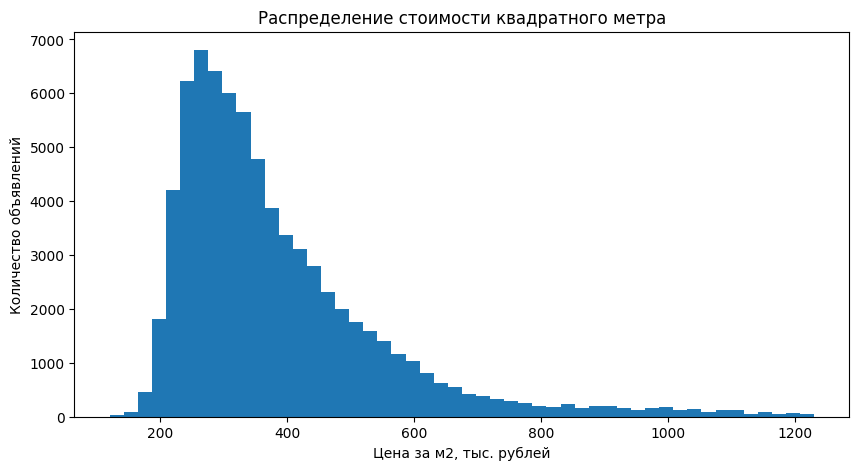

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(flats["price_m2_t"].dropna(), bins=50)
ax.set_title("Распределение стоимости квадратного метра")
ax.set_xlabel("Цена за м2, тыс. рублей")
ax.set_ylabel("Количество объявлений")

plt.show()


In [14]:
source_stats = (flats.groupby("source").agg(
    listings=("price", "size"),
    median_price_mln=("price_mln", "median"),
    median_price_m2_t=("price_m2_t", "median"),
    median_square=("total_square", "median")).sort_values("listings", ascending=False))
source_stats

,listings,median_price_mln,median_price_m2_t,median_square
source,,,,
ЦИАН,36640,20.79,350.00,64.10
Домклик,19277,13.30,300.00,46.00
Яндекс.Недвижимость,8806,16.70,341.23,51.00
Новострой-М,8457,18.47,364.34,53.30


In [15]:
#сравнение по районам
district_stats = (flats.groupby("district").agg(listings=("price", "size"), median_price_mln=("price_mln", "median"), median_price_m2_t=("price_m2_t", "median")).query("listings >= 20").sort_values("median_price_m2_t", ascending=False))

district_stats.head(15)

,listings,median_price_mln,median_price_m2_t
district,,,
Хамовники район,1186,110.00,769.31
Арбат район,516,84.74,741.34
Замоскворечье район,778,39.31,570.09
Дорогомилово район,923,35.00,561.21
Тверской район,862,54.29,545.80
Беговой район,747,35.05,536.84
Пресненский район,2237,43.00,529.80
Раменки район,3397,41.02,518.95
Марфино район,1328,27.50,500.47


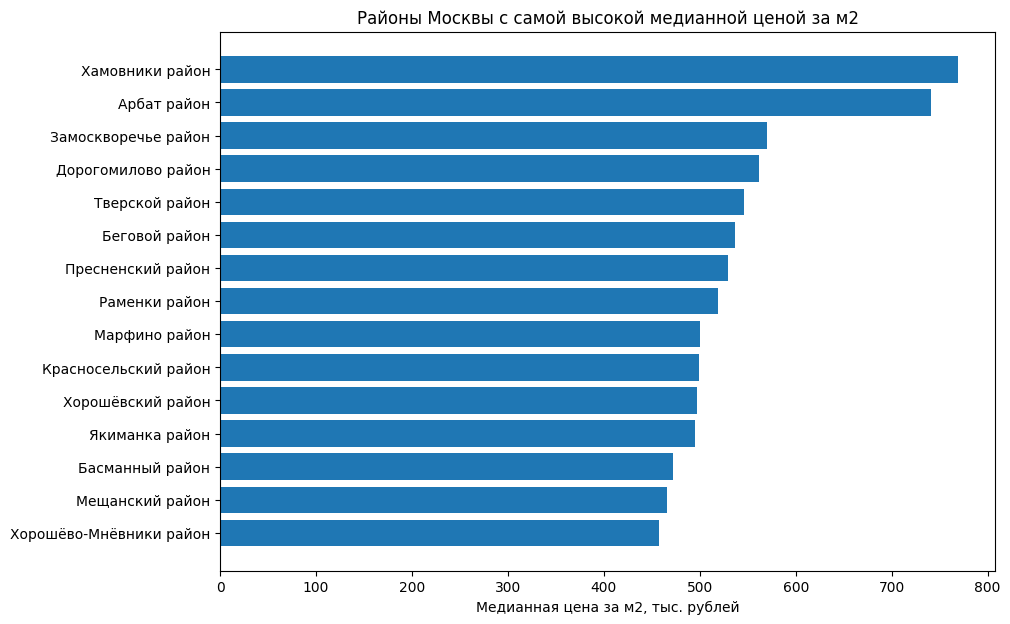

In [17]:
top_districts = district_stats.head(15).sort_values("median_price_m2_t")
fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(top_districts.index, top_districts["median_price_m2_t"])
ax.set_title("Районы Москвы с самой высокой медианной ценой за м2")
ax.set_xlabel("Медианная цена за м2, тыс. рублей")
ax.set_ylabel("")

plt.show()

In [23]:
room_stats = (flats.groupby("rooms").agg( #количество комнат
        listings=("price", "size"),
        median_price_mln=("price_mln", "median"),
        median_square=("total_square", "median"),
        median_m2_t=("price_m2_t", "median")))

room_stats

,listings,median_price_mln,median_square,median_m2_t
rooms,,,,
1.00,18498,12.10,37.10,344.45
2.00,25052,17.30,55.40,322.14
3.00,19432,25.00,77.70,319.30
4.00,5719,51.00,118.00,416.67
5.00,1532,104.00,188.50,535.40
6.00,626,158.75,288.85,546.40
7.00,45,159.00,305.00,530.86
8.00,23,185.00,336.40,553.89
9.00,11,330.00,588.83,623.05


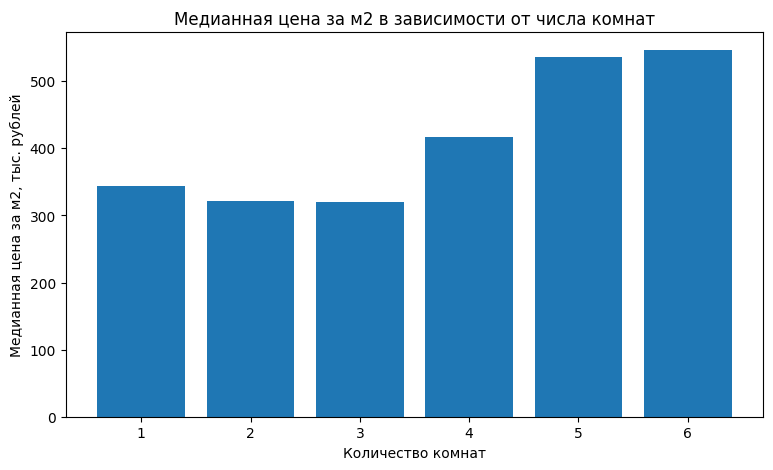

In [24]:
room_stats_plot = room_stats[room_stats["listings"] >= 100].copy()
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(room_stats_plot.index.astype(int).astype(str), room_stats_plot["median_m2_t"])
ax.set_title("Медианная цена за м2 в зависимости от числа комнат")
ax.set_xlabel("Количество комнат")
ax.set_ylabel("Медианная цена за м2, тыс. рублей")

plt.show()

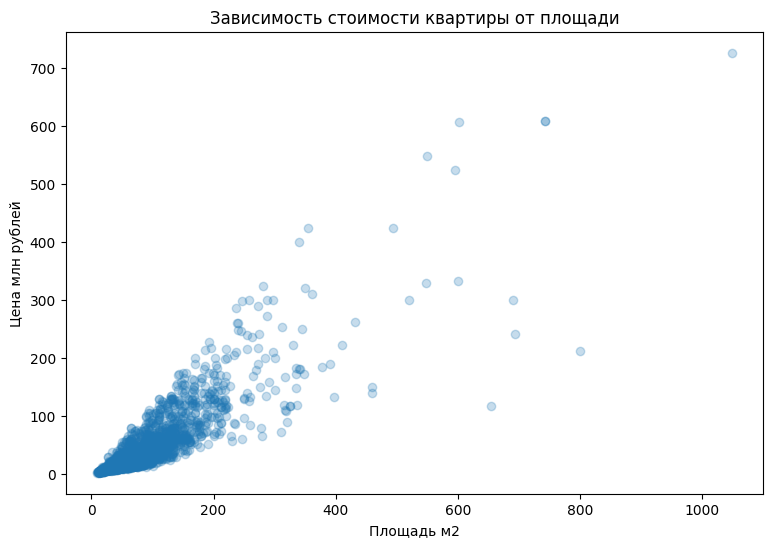

In [25]:
sample = flats.dropna(subset=["total_square", "price_mln"]).sample(min(5000, len(flats)), random_state=42)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(sample["total_square"], sample["price_mln"], alpha=0.25)

ax.set_xlabel("Площадь м2")
ax.set_ylabel("Цена млн рублей")
ax.set_title("Зависимость стоимости квартиры от площади")

plt.show()

Из-за объектов элитного сегмента основная масса значений на графике сжата. Поэтому отдельно посмотрим без этих объявлений


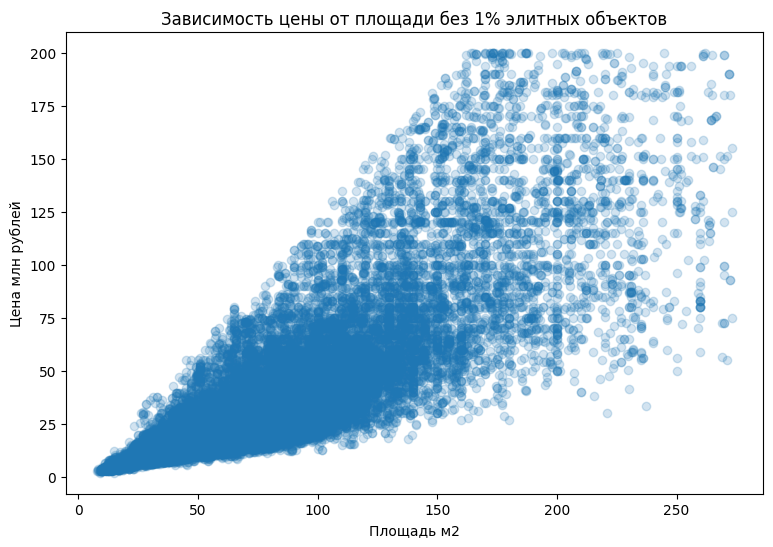

In [26]:
square_limit = flats["total_square"].quantile(0.99)
price_limit = flats["price"].quantile(0.99)
typical = flats[(flats["total_square"] <= square_limit) & (flats["price"] <= price_limit)]

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(typical["total_square"], typical["price_mln"], alpha=0.20)
ax.set_xlabel("Площадь м2")
ax.set_ylabel("Цена млн рублей")
ax.set_title("Зависимость цены от площади без 1% элитных объектов")

plt.show()

In [27]:
Red_Square_lat = 55.75417 #информация с сайта https://time365.info/places/object/5163
Red_Square_lon = 37.62

def haversine_distance(lat, lon, center_lat=Red_Square_lat, center_lon=Red_Square_lon):
    earth_radius = 6371  
    lat = radians(lat)
    lon = radians(lon)
    center_lat = radians(center_lat)
    center_lon = radians(center_lon)
    # по формуле гаверсинуса
    dlat = lat - center_lat
    dlon = lon - center_lon
    a = (sin(dlat / 2) ** 2 + cos(center_lat) * cos(lat) * sin(dlon / 2) ** 2) 
    return 2 * earth_radius * arcsin(sqrt(a)) 

In [28]:
flats["distance_to_center_km"] = haversine_distance(flats["lat"], flats["lon"])

flats[["address_name","lat", "lon", "distance_to_center_km"]].head(10)

,address_name,lat,lon,distance_to_center_km
0,"2-й Щемиловский переулок, 5а",55.78,37.61,2.84
1,"Харлампиева, 46",55.55,37.31,29.68
2,"ЖК Прокшино, 8 к4",55.59,37.43,21.31
3,"ЖК Прокшино, 6 к2",55.59,37.43,21.46
4,"Давыдковская, 18",55.72,37.46,10.42
9,"улица Академика Королёва, 21",55.82,37.60,7.41
10,"Кулакова, 1 к2",55.82,37.40,15.22
11,"Новохохловская, вл15 к4",55.73,37.71,6.47
12,"улица Бориса Пастернака, 31 к1",55.64,37.31,23.21
16,"Серебряническая набережная, 19",55.75,37.65,1.92


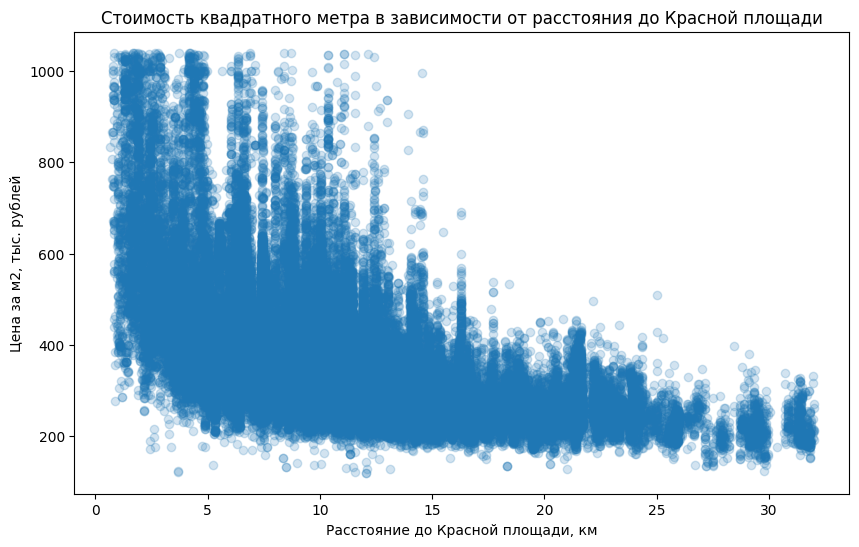

In [29]:
geo = flats.dropna(subset=["distance_to_center_km", "price_m2_t"]).copy()

limit = geo["price_m2_t"].quantile(0.99)
geo_plot = geo[geo["price_m2_t"] <= limit]

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(geo_plot["distance_to_center_km"], geo_plot["price_m2_t"], alpha=0.20)
ax.set_title("Стоимость квадратного метра в зависимости от расстояния до Красной площади")
ax.set_xlabel("Расстояние до Красной площади, км")
ax.set_ylabel("Цена за м2, тыс. рублей")

plt.show()

In [32]:
bins = [0, 3, 5, 10, 15, 20, 30, float("inf")] #ценовые зоны по расстоянию
labels = [
    "0–3 км",
    "3–5 км",
    "5–10 км",
    "10–15 км",
    "15–20 км",
    "20–30 км",
    "30+ км"
]

flats["distance_group"] = pd.cut(
    flats["distance_to_center_km"],
    bins=bins,
    labels=labels,
    right=False
)

distance_stats = (
    flats.groupby("distance_group", observed=True)
    .agg(
        listings=("price", "size"),
        median_price_mln=("price_mln", "median"),
        median_m2_t=("price_m2_t", "median"),
        median_square=("total_square", "median")
    )
)
distance_stats

,listings,median_price_mln,median_m2_t,median_square
distance_group,,,,
0–3 км,4253,65.00,641.18,103.10
3–5 км,6092,30.00,453.70,68.35
5–10 км,22744,23.95,399.79,61.80
10–15 км,22649,16.35,316.95,54.00
15–20 км,8718,14.00,264.93,53.70
20–30 км,8192,13.14,250.85,54.00
30+ км,532,11.33,204.50,58.50


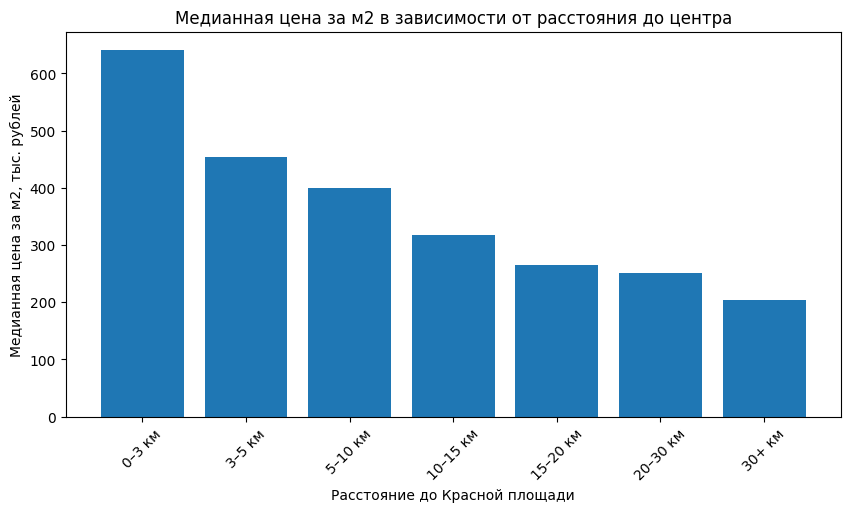

In [33]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(distance_stats.index.astype(str), distance_stats["median_m2_t"])
ax.set_title("Медианная цена за м2 в зависимости от расстояния до центра")
ax.set_xlabel("Расстояние до Красной площади")
ax.set_ylabel("Медианная цена за м2, тыс. рублей")

plt.xticks(rotation=45)
plt.show()

In [34]:
district_geo = ( #таблица районов по расстоянию и цене
    flats.groupby("district").agg(
        listings=("price", "size"),
        median_distance_km=("distance_to_center_km", "median"),
        median_m2_th=("price_m2_t", "median")).query("listings >= 20").sort_values("median_distance_km"))

district_geo.head(15)

,listings,median_distance_km,median_m2_th
district,,,
Арбат район,516,1.72,741.34
Красносельский район,345,2.43,498.97
Тверской район,862,2.55,545.80
Басманный район,1160,2.74,472.35
Мещанский район,440,2.85,465.88
Замоскворечье район,778,2.96,570.09
Якиманка район,482,3.29,494.47
Таганский район,595,3.38,415.82
Хамовники район,1186,3.44,769.31


In [37]:
#стоимость квартиры на первом этаже и на других этажах
flats["price_per"] = flats["price"] / flats["total_square"]
first_floor = flats.loc[flats["floor"] == 1, "price_per"].dropna()

other_floors = flats.loc[flats["floor"] != 1, "price_per"].dropna()

print(f"Первый этаж - {len(first_floor):,} объектов")
print(f"Остальные этажи - {len(other_floors):,} объектов")

print(f"Медианная цена за м2 первый этаж " f"{first_floor.median() / 1000:.1f} тыс. рублей")
print(f"Медианная цена за м2 остальные этажи: " f"{other_floors.median() / 1000:.1f} тыс. рублей")

Первый этаж - 3,514 объектов
Остальные этажи - 69,666 объектов
Медианная цена за м2 первый этаж 276.3 тыс. рублей
Медианная цена за м2 остальные этажи: 341.2 тыс. рублей


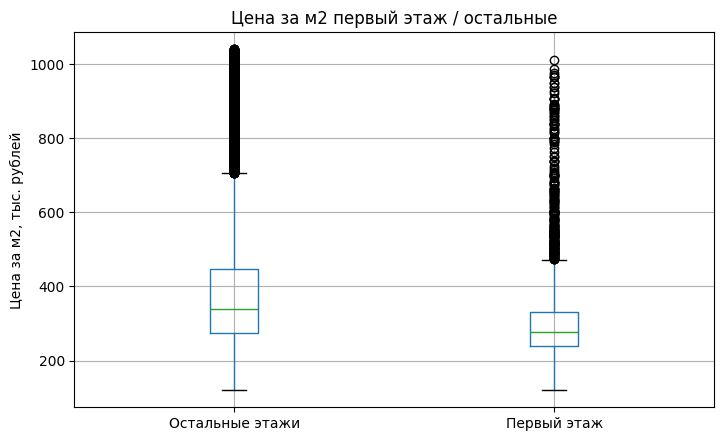

In [41]:
flats["price_per_t"] = (flats["price"] / flats["total_square"]) / 1000
plot_data = flats[flats["floor"].notna() & flats["price_per_t"].notna()].copy()
plot_data["floor_group"] = np.where(plot_data["floor"] == 1, "Первый этаж", "Остальные этажи")

limit = plot_data["price_per_t"].quantile(0.99)

plot_data_filtered = plot_data[plot_data["price_per_t"] <= limit]

fig, ax = plt.subplots(figsize=(8, 5))
plot_data_filtered.boxplot(column="price_per_t", by="floor_group", ax=ax)
ax.set_title("Цена за м2 первый этаж / остальные")
ax.set_xlabel("")
ax.set_ylabel("Цена за м2, тыс. рублей")

plt.suptitle("")
plt.show()